# Разведочный анализ для музыкальной рекомендательной системы на Yambda-50M

Проект: рекомендации треков по истории прослушиваний и характеристикам треков. В этом ноутбуке я проверяю качество данных, смотрю на поведение пользователей, определяю целевую переменную и готовлю матрицу взаимодействий для чекпоинта 3.

## 1. Среда и данные

In [1]:
import os, json
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from huggingface_hub import hf_hub_download

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pl.Config.set_tbl_rows(25)
sns.set_theme(style="whitegrid", context="notebook")

In [2]:
# Закреплённая версия датасета
REPO_ID = "yandex/yambda"
DATA_REVISION = "dd6f3a19eef5866e346c3270e098baa641a44948"

BASE_DIR = Path(os.environ.get("YAMBDA_BASE", "/content"))
DATA_DIR = BASE_DIR / "data" / "yambda"
ARTIFACT_DIR = BASE_DIR / "artifacts" / "eda"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

SECONDS_PER_DAY = 86_400
MIN_PLAYED_RATIO = 50
CUTOFF_DAY = 271
WINDOW_DAYS = 30

def fetch(filename: str) -> Path:
    local = DATA_DIR / filename
    if local.exists():
        return local
    return Path(hf_hub_download(repo_id=REPO_ID, repo_type="dataset", filename=filename, revision=DATA_REVISION, local_dir=DATA_DIR))

def collect(lf):
    return lf.collect(engine="streaming")

def pct(a, b):
    return 100.0 * a / b if b else float("nan")

def gini(values):
    x = np.sort(np.asarray(values, dtype=np.float64))
    n = x.size
    return float((2 * np.arange(1, n + 1) - n - 1) @ x / (n * x.sum()))

RAW_PATH = fetch("flat/50m/multi_event.parquet")
ARTIST_PATH = fetch("artist_item_mapping.parquet")
ALBUM_PATH = fetch("album_item_mapping.parquet")
raw = pl.scan_parquet(RAW_PATH)
print(raw.collect_schema())

flat/50m/multi_event.parquet: reconstructing file:   0%|          |  0.00B /  384MB            

flat/50m/multi_event.parquet: downloading bytes:           |  0.00B            

artist_item_mapping.parquet: reconstructing file:   0%|          |  0.00B / 38.3MB            

artist_item_mapping.parquet: downloading bytes:           |  0.00B            

album_item_mapping.parquet: reconstructing file:   0%|          |  0.00B / 54.5MB            

album_item_mapping.parquet: downloading bytes:           |  0.00B            

Schema({'uid': UInt32, 'timestamp': UInt32, 'item_id': UInt32, 'is_organic': UInt8, 'played_ratio_pct': UInt16, 'track_length_seconds': UInt32, 'event_type': Enum(categories=['listen', 'dislike', 'like', 'undislike', 'unlike'])})


В датасете есть прослушивания с долей проигрывания, лайки и дизлайки, признак органика/рекомендации и связи треков с артистами и альбомами. Беру версию 50M, полная содержит 5 млрд событий.

In [3]:
overview = collect(raw.select(
    pl.len().alias("n_events"),
    pl.col("uid").n_unique().alias("n_users"),
    pl.col("item_id").n_unique().alias("n_items"),
    (pl.col("timestamp").max() / SECONDS_PER_DAY).alias("period_days"),
))
display(overview)
display(collect(raw.head(5)))

n_events,n_users,n_items,period_days
u32,u32,u32,f64
47790449,10000,934057,300.925926


uid,timestamp,item_id,is_organic,played_ratio_pct,track_length_seconds,event_type
u32,u32,u32,u8,u16,u32,enum
100,39420,8326270,0,100,170,"""listen"""
100,39420,1441281,0,100,105,"""listen"""
100,39625,286361,0,100,185,"""listen"""
100,40110,732449,0,100,240,"""listen"""
100,40360,3397170,0,46,130,"""listen"""


## 2. Качество данных

In [4]:
listen_raw = raw.filter(pl.col("event_type") == "listen")

display(collect(listen_raw.select("played_ratio_pct", "track_length_seconds"))
        .describe(percentiles=(0.01, 0.25, 0.5, 0.75, 0.99)))

crosstab = (
    collect(raw.group_by("event_type", "is_organic").agg(pl.len().alias("n")))
    .with_columns(pl.col("is_organic").cast(pl.String))
    .pivot(on="is_organic", index="event_type", values="n")
    .fill_null(0)
    .with_columns((pl.col("0").cast(pl.Int64) + pl.col("1").cast(pl.Int64)).alias("total"))
    .with_columns(
        (100 * pl.col("total") / pl.col("total").sum()).alias("share_pct"),
        (100 * pl.col("1") / pl.col("total")).alias("organic_pct"),
    )
    .select("event_type", "0", "1", "total", "share_pct", "organic_pct")
    .sort("total", descending=True)
)
display(crosstab)

statistic,played_ratio_pct,track_length_seconds
str,f64,f64
"""count""",4.6467212e7,4.6467212e7
"""null_count""",0.0,0.0
"""mean""",64.759486,207.411753
"""std""",44.088534,89.210895
"""min""",0.0,5.0
"""1%""",0.0,95.0
"""25%""",7.0,165.0
"""50%""",100.0,200.0
"""75%""",100.0,230.0


event_type,0,1,total,share_pct,organic_pct
enum,u32,u32,i64,f64,f64
"""listen""",22463555,24003657,46467212,97.231169,51.657192
"""like""",379255,502201,881456,1.844419,56.974029
"""unlike""",16531,296441,312972,0.654884,94.718058
"""dislike""",51788,55988,107776,0.225518,51.948486
"""undislike""",2324,18709,21033,0.044011,88.950697


In [5]:
missing = collect(raw.group_by("event_type").agg(
    pl.len().alias("n_events"),
    pl.col("played_ratio_pct").null_count().alias("ratio_nulls"),
    pl.col("track_length_seconds").null_count().alias("length_nulls"),
)).sort("n_events", descending=True)
display(missing)
other = collect(raw.select(pl.col("uid", "timestamp", "item_id", "is_organic", "event_type").null_count()))
print("Пропуски в остальных столбцах:", sum(other.row(0)))

event_type,n_events,ratio_nulls,length_nulls
enum,u32,u32,u32
"""listen""",46467212,0,0
"""like""",881456,881456,881456
"""unlike""",312972,312972,312972
"""dislike""",107776,107776,107776
"""undislike""",21033,21033,21033


Пропуски в остальных столбцах: 0


Пропуски есть только в `played_ratio_pct` и `track_length_seconds`, по 2,77% строк, и они совпадают с реакциями (like, unlike, dislike, undislike). Пропуски структурные, заполнять их незачем: признаки прослушивания я считаю только по событиям listen.

In [6]:
validity = collect(listen_raw.select(
    ((pl.col("played_ratio_pct") == 0).mean() * 100).alias("ratio_eq_0_pct"),
    ((pl.col("played_ratio_pct") > 100).mean() * 100).alias("ratio_gt_100_pct"),
    pl.col("played_ratio_pct").max().alias("ratio_max"),
    (pl.col("track_length_seconds") == 0).sum().alias("length_eq_0"),
    (pl.col("track_length_seconds") % 5 != 0).sum().alias("length_not_mult_5"),
    ((pl.col("track_length_seconds") > 1800).mean() * 100).alias("length_gt_30min_pct"),
    pl.col("track_length_seconds").max().alias("length_max"),
)).with_columns(
    pl.lit(collect(raw.select((pl.col("timestamp") % 5 != 0).sum())).item()).alias("ts_not_mult_5"),
)
display(validity)

item_len = collect(listen_raw.group_by("item_id").agg(
    pl.col("track_length_seconds").n_unique().alias("n_lengths"),
    pl.col("track_length_seconds").first().alias("length"),
))
print("Треков с несогласованной длительностью:", item_len.filter(pl.col("n_lengths") > 1).height)

ratio_eq_0_pct,ratio_gt_100_pct,ratio_max,length_eq_0,length_not_mult_5,length_gt_30min_pct,length_max,ts_not_mult_5
f64,f64,u16,u32,u32,f64,u32,i32
7.448865,0.46946,159,0,0,0.067927,2495,0


Треков с несогласованной длительностью: 0


In [7]:
ratio_counts = collect(listen_raw.group_by("played_ratio_pct").agg(pl.len().alias("n")).sort("played_ratio_pct"))
ratio_by_len = collect(
    listen_raw.with_columns(pl.col("track_length_seconds").cut([90, 150, 240, 360, 600]).alias("length_bin"))
    .group_by("length_bin").agg(
        pl.col("track_length_seconds").min().alias("min_len"),
        pl.len().alias("n_listens"),
        ((pl.col("played_ratio_pct") == 0).mean() * 100).alias("eq_0_pct"),
        ((pl.col("played_ratio_pct") == 100).mean() * 100).alias("eq_100_pct"),
        (pl.col("played_ratio_pct").is_between(101, 105).mean() * 100).alias("r101_105_pct"),
        ((pl.col("played_ratio_pct") > 120).mean() * 100).alias("gt_120_pct"),
    )
).sort("min_len").drop("min_len")
display(ratio_by_len)



length_bin,n_listens,eq_0_pct,eq_100_pct,r101_105_pct,gt_120_pct
cat,u32,f64,f64,f64,f64
"""(-inf, 90]""",463448,2.923305,51.283855,0.83634,0.099256
"""(90, 150]""",7473311,4.959689,52.843084,0.502843,0.123894
"""(150, 240]""",29280012,7.172917,54.032638,0.278248,0.099576
"""(240, 360]""",8190899,10.09988,51.819196,0.115091,0.091357
"""(360, 600]""",925055,13.577463,46.320273,0.107129,0.106156
"""(600, inf]""",134487,17.829233,39.857384,0.678876,0.24612


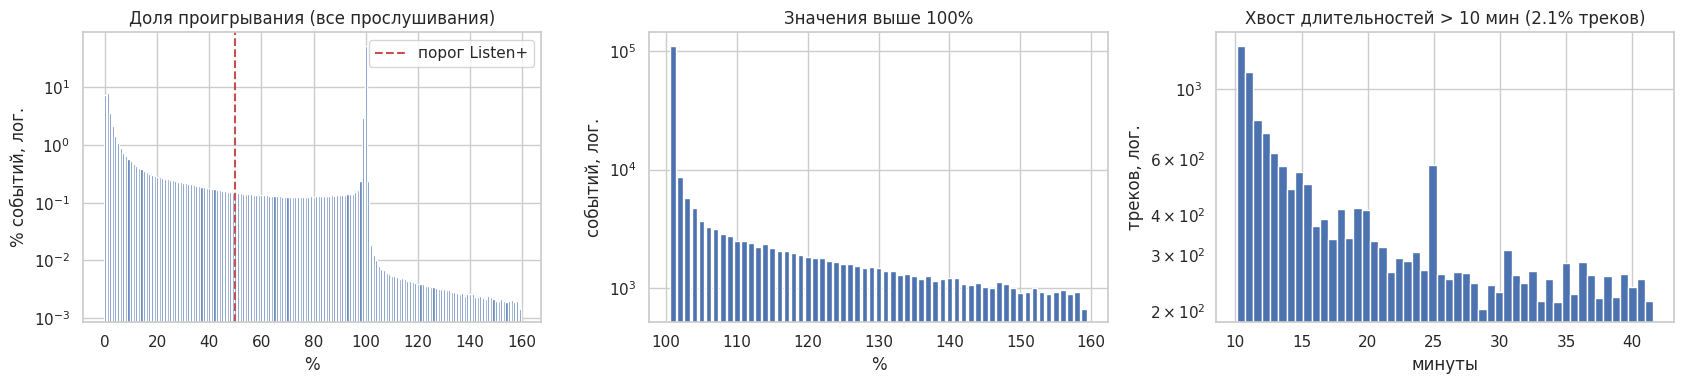

In [8]:
lengths_min = item_len["length"].to_numpy() / 60
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].bar(ratio_counts["played_ratio_pct"], 100 * ratio_counts["n"] / ratio_counts["n"].sum())
axes[0].set(yscale="log", title="Доля проигрывания (все прослушивания)", xlabel="%", ylabel="% событий, лог.")
axes[0].axvline(MIN_PLAYED_RATIO, color="C3", ls="--", label="порог Listen+")
axes[0].legend()
over = ratio_counts.filter(pl.col("played_ratio_pct") > 100)
axes[1].bar(over["played_ratio_pct"], over["n"])
axes[1].set(yscale="log", title="Значения выше 100%", xlabel="%", ylabel="событий, лог.")
if (lengths_min > 10).any():
    axes[2].hist(lengths_min[lengths_min > 10], bins=50, log=True)
axes[2].set(title=f"Хвост длительностей > 10 мин ({(lengths_min > 10).mean():.1%} треков)",
            xlabel="минуты", ylabel="треков, лог.")
plt.tight_layout(); plt.show()

Ошибочных значений проверки не нашли: длительность положительна и одинакова внутри трека, категории корректны, timestamp и длительности кратны 5 секундам.

Ноль процентов (7,45% прослушиваний) означает мгновенный пропуск, у длинных треков таких пропусков больше. Эти события оставляю, но положительным сигналом не считаю. Значения больше 100% встречаются у 0,47% прослушиваний, почти половина из них ровно 101%, скорее всего это округление и перемотка. Их не обрезаю. Длинные треки (больше 30 минут) дают 0,07% прослушиваний, скопления у максимума нет, обрезки тоже.

In [9]:
dup = collect(raw.group_by(raw.collect_schema().names()).agg(pl.len().alias("copies")).filter(pl.col("copies") > 1))
display(dup.group_by("event_type").agg(
    pl.len().alias("groups"),
    (pl.col("copies").cast(pl.UInt64) - 1).sum().alias("extra_rows"),
    pl.col("copies").max().alias("max_copies"),
    ((pl.col("played_ratio_pct") == 0).mean() * 100).alias("ratio_0_pct"),
).sort("extra_rows", descending=True))
display(dup.sort(["copies", "uid", "timestamp", "item_id"], descending=[True, False, False, False]).head(5))
print(f"Лишних строк: {int((dup['copies'].cast(pl.UInt64) - 1).sum()):,} "
      f"({pct(int((dup['copies'].cast(pl.UInt64) - 1).sum()), overview['n_events'].item()):.2f}%)")

event_type,groups,extra_rows,max_copies,ratio_0_pct
enum,u32,u64,u32,f64
"""listen""",134770,225625,124,25.737924
"""like""",4163,6405,46,null
"""unlike""",2738,3708,47,null
"""dislike""",201,248,9,null
"""undislike""",232,244,5,null


uid,timestamp,item_id,is_organic,played_ratio_pct,track_length_seconds,event_type,copies
u32,u32,u32,u8,u16,u32,enum,u32
56300,1783385,7891609,1,0,175,"""listen""",124
56300,1783400,7891609,1,0,175,"""listen""",113
56300,1783395,7891609,1,0,175,"""listen""",112
56300,1783405,7891609,1,0,175,"""listen""",102
945800,25995405,2718138,1,100,1990,"""listen""",100


Лишних строк: 236,230 (0.49%)


В данных 236 230 полных копий строк, до 124 копий в группе. Сто прослушиваний одного трека за 5 секунд невозможны, это артефакт логирования. Удаляю точные копии и дальше работаю с очищенной таблицей.

In [10]:
DEDUP_PATH = DATA_DIR / "multi_event_dedup_v2.parquet"
if not DEDUP_PATH.exists():
    collect(raw.unique().sort(["uid", "timestamp", "item_id", "event_type", "played_ratio_pct", "is_organic"],
                              nulls_last=True)).write_parquet(DEDUP_PATH)

events = pl.scan_parquet(DEDUP_PATH)
listens = events.filter(pl.col("event_type") == "listen")
POSITIVE = (pl.col("event_type") == "listen") & (pl.col("played_ratio_pct") >= MIN_PLAYED_RATIO)
print("Число событий после удаления точных дубликатов:", collect(events.select(pl.len())).item())

Число событий после удаления точных дубликатов: 47554219


## 3. Метаданные артистов и альбомов

In [11]:
artist_map = pl.scan_parquet(ARTIST_PATH)
album_map = pl.scan_parquet(ALBUM_PATH)
catalog = collect(events.select("item_id").unique())

item_artist = collect(artist_map.join(catalog.lazy(), on="item_id", how="semi"))
item_album = collect(album_map.join(catalog.lazy(), on="item_id", how="semi"))
first_artist = item_artist.group_by("item_id").agg(pl.col("artist_id").min())

item_meta = (
    catalog
    .join(item_artist.group_by("item_id").agg(pl.len().alias("n_artists")), on="item_id", how="left")
    .join(item_album.group_by("item_id").agg(pl.len().alias("n_albums")), on="item_id", how="left")
    .with_columns(pl.col("n_artists", "n_albums").fill_null(0))
)
display(item_meta.select(
    pl.len().alias("n_items"),
    ((pl.col("n_artists") > 0).mean() * 100).alias("artist_coverage_pct"),
    ((pl.col("n_albums") > 0).mean() * 100).alias("album_coverage_pct"),
    (pl.col("n_artists") > 1).sum().alias("multi_artist_items"),
    pl.col("n_albums").max().alias("max_albums"),
    pl.col("n_albums").quantile(0.99).alias("p99_albums"),
))

n_items,artist_coverage_pct,album_coverage_pct,multi_artist_items,max_albums,p99_albums
u32,f64,f64,u32,u32,f64
934057,99.399715,96.54732,346,241,8.0


Артист известен у 99,4% треков каталога, альбом у 96,5%. Названий и жанров нет, только идентификаторы, так что из контентных признаков у нас артист и альбом. Артиста дальше использую как проверочную метку для эмбеддингов, но жанр он не заменяет. У трека бывает до 241 альбома (сборники), но у 99% треков их не больше 8.

## 4. Поведение пользователей

### 4.1. Активность и отбор пользователей

In [12]:
user_activity = collect(
    events.with_columns((pl.col("timestamp") // SECONDS_PER_DAY).alias("day"))
    .group_by("uid").agg(
        pl.len().alias("n_events"),
        (pl.col("event_type") == "listen").sum().alias("n_listens"),
        (pl.col("event_type") == "like").sum().alias("n_likes"),
        pl.col("item_id").n_unique().alias("n_items"),
        pl.col("day").n_unique().alias("n_active_days"),
        pl.col("day").min().alias("first_day"),
        pl.col("day").max().alias("last_day"),
    )
)
display(user_activity.drop("uid").describe(percentiles=(0.05, 0.5, 0.95)))
display(user_activity.select(
    ((pl.col("last_day") >= CUTOFF_DAY).mean() * 100).alias("active_after_cutoff_pct"),
    ((pl.col("last_day") >= 294).mean() * 100).alias("active_last_week_pct"),
    ((pl.col("first_day") <= 7).mean() * 100).alias("seen_first_week_pct"),
    (pl.col("first_day") >= CUTOFF_DAY).sum().alias("first_seen_after_cutoff"),
    (pl.col("n_listens") == 0).sum().alias("users_without_listens"),
))



statistic,n_events,n_listens,n_likes,n_items,n_active_days,first_day,last_day
str,f64,f64,f64,f64,f64,f64,f64
"""count""",10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",4755.4219,4624.1587,87.5051,1360.7096,107.5989,70.5984,297.6892
"""std""",5536.263781,5448.052609,182.533581,1301.733098,84.734313,92.32041,3.459104
"""min""",10.0,0.0,0.0,2.0,2.0,0.0,286.0
"""5%""",59.0,0.0,0.0,46.0,7.0,0.0,289.0
"""50%""",2640.0,2559.0,27.0,989.0,86.0,13.0,299.0
"""95%""",16989.0,16731.0,363.0,3951.0,266.0,260.0,300.0
"""max""",27697.0,27616.0,5626.0,9963.0,301.0,285.0,300.0


active_after_cutoff_pct,active_last_week_pct,seen_first_week_pct,first_seen_after_cutoff,users_without_listens
f64,f64,f64,u32,u32
100.0,86.56,45.64,302,762


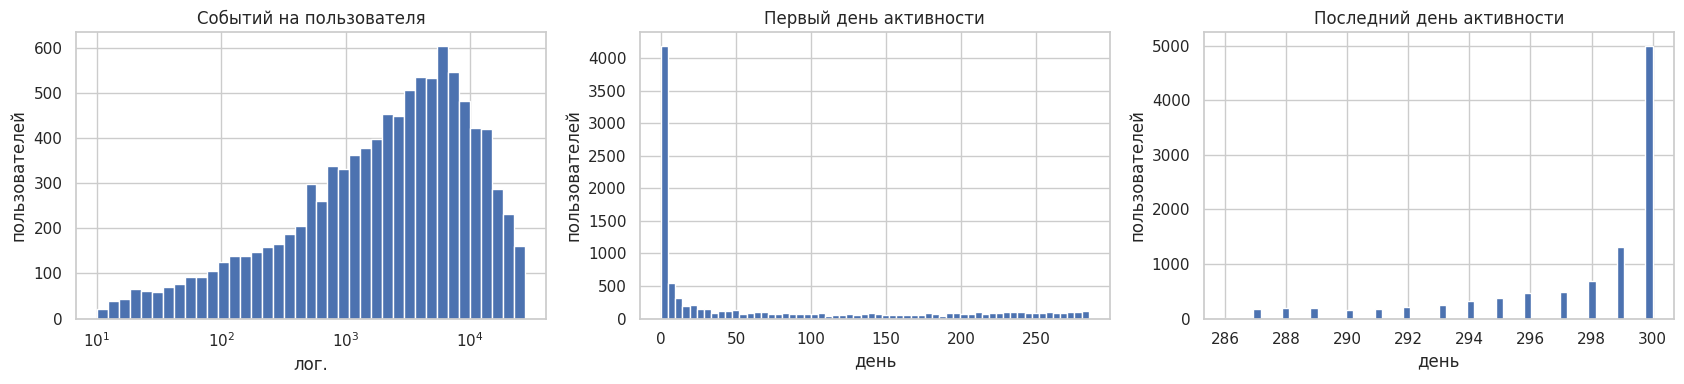

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
v = user_activity["n_events"].to_numpy()
axes[0].hist(v, bins=np.geomspace(v.min(), v.max() + 1, 40)); axes[0].set(xscale="log", title="Событий на пользователя", xlabel="лог.")
axes[1].hist(user_activity["first_day"], bins=60); axes[1].set(title="Первый день активности", xlabel="день")
axes[2].hist(user_activity["last_day"], bins=60); axes[2].set(title="Последний день активности", xlabel="день")
for ax in axes: ax.set_ylabel("пользователей")
plt.tight_layout(); plt.show()

Активность очень неравномерная: медиана 2 640 событий, 95-й перцентиль в 6,4 раза больше. В выборке заметен отбор: у всех 10 000 пользователей последний активный день не раньше 286-го, а первые дни разбросаны по всему периоду. Никто не уходит, это похоже на условие «активен в конце периода», поэтому тренды во времени описывают когорту, а не сервис. 7,6% пользователей ставили реакции, но не слушали ни одного трека, для модели они холодные.

### 4.2. Концентрация популярности

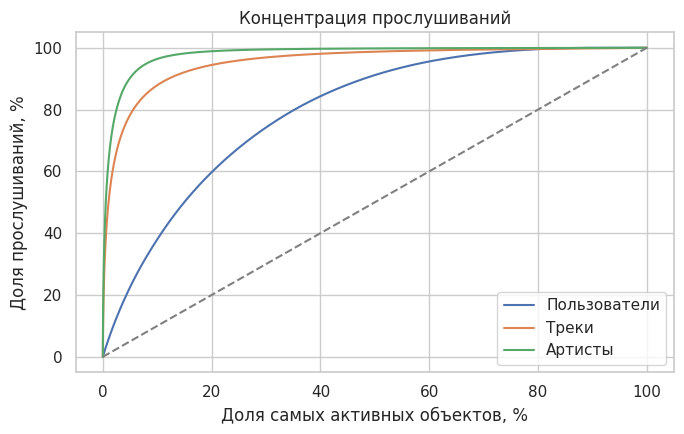

In [14]:
item_stats = collect(listens.group_by("item_id").agg(pl.len().alias("n_listens")))
artist_listens = item_stats.join(first_artist, on="item_id", how="inner").group_by("artist_id").agg(pl.col("n_listens").sum())
populations = {
    "Пользователи": user_activity["n_listens"].to_numpy(),
    "Треки": item_stats["n_listens"].to_numpy(),
    "Артисты": artist_listens["n_listens"].to_numpy(),
}
rows = []
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, x in populations.items():
    s = np.sort(x.astype(np.float64))[::-1]
    cum = 100 * np.r_[0, np.cumsum(s)] / s.sum()
    n = s.size
    idx = np.unique(np.linspace(0, n, min(n + 1, 2000), dtype=int))
    ax.plot(100 * idx / n, cum[idx], label=name)
    rows.append({"population": name, "n": n, "gini": round(gini(x), 3),
                 **{f"top{p}pct_share": round(cum[int(np.ceil(n * p / 100))], 1) for p in (1, 5, 20)}})
ax.plot([0, 100], [0, 100], "--", color="gray")
ax.set(xlabel="Доля самых активных объектов, %", ylabel="Доля прослушиваний, %", title="Концентрация прослушиваний")
ax.legend(); plt.tight_layout(); plt.show()


In [15]:
display(pl.DataFrame(rows))

population,n,gini,top1pct_share,top5pct_share,top20pct_share
str,i64,f64,f64,f64,f64
"""Пользователи""",10000,0.591,5.5,22.5,59.7
"""Треки""",877168,0.907,49.1,78.3,94.4
"""Артисты""",144485,0.96,62.4,90.2,98.9


По пользователям концентрация умеренная (Джини 0,59), по трекам экстремальная: 1% треков даёт 49% прослушиваний. По артистам ещё сильнее: 1% артистов собирает 62% прослушиваний. Популярность нельзя считать выбросом, это главный сигнал, но бейзлайн «самое популярное» будет плохим по разнообразию.

### 4.3. Повторные прослушивания

In [16]:
pair_counts = collect(listens.group_by("uid", "item_id").agg(pl.len().alias("n")))
total = int(pair_counts["n"].sum())
display(pl.DataFrame({
    "unique_pairs": [pair_counts.height],
    "pairs_with_repeats_pct": [pct(pair_counts.filter(pl.col("n") > 1).height, pair_counts.height)],
    "listens_beyond_first_pct": [pct(total - pair_counts.height, total)],
    "p99_listens_per_pair": [pair_counts["n"].quantile(0.99)],
    "max_listens_per_pair": [pair_counts["n"].max()],
}))


unique_pairs,pairs_with_repeats_pct,listens_beyond_first_pct,p99_listens_per_pair,max_listens_per_pair
i64,f64,f64,f64,i64
13268889,45.879908,71.305291,33.0,4275


Почти половина пар пользователь-трек повторяется, 71% прослушиваний составляют повторы. У числа повторов на пару тяжёлый хвост (максимум 4 275 за 300 дней), поэтому в матрице беру бинарные веса или `log1p(count)`, а не сырые счётчики.

## 5. Сигнал и целевая переменная

### 5.1. Что считать положительным взаимодействием

In [17]:
pair_max = collect(listens.group_by("uid", "item_id").agg(pl.col("played_ratio_pct").max().alias("max_ratio")))
n_listens_all = int(ratio_counts["n"].sum())
display(pl.DataFrame([{
    "listens_kept_pct": pct(int(ratio_counts.filter(pl.col("played_ratio_pct") >= t)["n"].sum()), n_listens_all),
    "pairs_kept_pct": pct(pair_max.filter(pl.col("max_ratio") >= t).height, pair_max.height),
    "users_kept": pair_max.filter(pl.col("max_ratio") >= t)["uid"].n_unique(),
} for t in (1, 30, 50, 80, 100)]))
del pair_max

listens_kept_pct,pairs_kept_pct,users_kept
f64,f64,i64
92.551135,96.578726,9237
67.004973,71.639781,9222
63.354948,68.100841,9209
59.344748,65.138182,9198
53.698636,60.107188,9189


Положительным взаимодействием считаю прослушивание с долей проигрывания не меньше 50%, как Listen+ у авторов Yambda. Распределение доли бимодальное, главный обрыв приходится на участок от 1% до 30%, где отсекаются пропуски, поэтому порог внутри 30-80% мало влияет на результат.

### 5.2. Временное разбиение

In [18]:
CUTOFF_TS = CUTOFF_DAY * SECONDS_PER_DAY
WINDOW_START = CUTOFF_TS - WINDOW_DAYS * SECONDS_PER_DAY
hist = events.filter(pl.col("timestamp") < CUTOFF_TS)
fut = events.filter(pl.col("timestamp") >= CUTOFF_TS)
hist_listens = hist.filter(pl.col("event_type") == "listen")

display(pl.concat([collect(t.select(
    pl.lit(name).alias("period"), pl.len().alias("n_events"),
    pl.col("uid").n_unique().alias("n_users"), pl.col("item_id").n_unique().alias("n_items"),
    POSITIVE.sum().alias("n_positive"))) for name, t in [("история: дни 0-270", hist), ("будущее: дни 271-300", fut)]]))

period,n_events,n_users,n_items,n_positive
str,u32,u32,u32,u32
"""история: дни 0-270""",41112120,9698,863544,25274806
"""будущее: дни 271-300""",6442099,10000,377673,4010691


Разбиваю по глобальной временной границе: всё до 271-го дня - история, последние 30 дней - будущее. Все решения о фильтрации и признаках дальше принимаю только по истории.

### 5.3. Что именно предстоит предсказывать

Раскладываю будущие положительные пары на непересекающиеся типы. Потом отдельно смотрю на доли холодных объектов, а не только пар.

In [19]:
hist_users = collect(hist.select("uid").unique())
hist_items = collect(hist.select("item_id").unique())
hist_pair_stats = collect(hist_listens.group_by("uid", "item_id").agg(
    pl.len().alias("n_hist"),
    (pl.col("played_ratio_pct") >= MIN_PLAYED_RATIO).sum().alias("n_pos_hist"),
    (pl.col("timestamp") >= WINDOW_START).sum().alias("n_hist_30d"),
    pl.col("timestamp").max().alias("last_ts"),
))
fut_pos = collect(fut.filter(POSITIVE).group_by("uid", "item_id").agg(pl.len().alias("n")))

user_artists_hist = hist_pair_stats.select("uid", "item_id").join(item_artist, on="item_id").select("uid", "artist_id").unique()
artist_known = (fut_pos.select("uid", "item_id").join(item_artist, on="item_id")
                .join(user_artists_hist, on=["uid", "artist_id"], how="semi")
                .select("uid", "item_id").unique().with_columns(pl.lit(True).alias("artist_known")))

target = (
    fut_pos
    .join(hist_users.with_columns(pl.lit(True).alias("user_known")), on="uid", how="left")
    .join(hist_items.with_columns(pl.lit(True).alias("item_known")), on="item_id", how="left")
    .join(hist_pair_stats.select("uid", "item_id").with_columns(pl.lit(True).alias("heard_before")), on=["uid", "item_id"], how="left")
    .join(artist_known, on=["uid", "item_id"], how="left")
    .join(item_artist.select("item_id").unique().with_columns(pl.lit(True).alias("has_artist")), on="item_id", how="left")
    .with_columns(pl.col("user_known", "item_known", "heard_before", "artist_known", "has_artist").fill_null(False))
    .with_columns(
        pl.when(~pl.col("user_known")).then(pl.lit("1. Холодный пользователь"))
        .when(~pl.col("item_known")).then(pl.lit("2. Холодный трек"))
        .when(pl.col("heard_before")).then(pl.lit("3. Повтор знакомого трека"))
        .when(pl.col("artist_known")).then(pl.lit("4. Новый трек знакомого артиста"))
        .when(~pl.col("has_artist")).then(pl.lit("5. Новый трек, артист неизвестен"))
        .otherwise(pl.lit("6. Новый артист")).alias("kind"),
        (pl.col("user_known") & pl.col("item_known") & ~pl.col("heard_before")).alias("is_new"),
    )
)


In [20]:
target_summary = target.group_by("kind").agg(pl.len().alias("pairs"), pl.col("n").sum().alias("events")).with_columns(
    (100 * pl.col("pairs") / pl.col("pairs").sum()).alias("pairs_pct"),
    (100 * pl.col("events") / pl.col("events").sum()).alias("events_pct"),
).sort("kind")
display(target_summary)

kind,pairs,events,pairs_pct,events_pct
str,u32,u32,f64,f64
"""1. Холодный пользователь""",62349,103405,2.7457,2.578234
"""2. Холодный трек""",118042,217038,5.198286,5.411486
"""3. Повтор знакомого трека""",1170953,2280258,51.565955,56.854492
"""4. Новый трек знакомого артист…",419815,634245,18.487643,15.813859
"""5. Новый трек, артист неизвест…",105,113,0.004624,0.002817
"""6. Новый артист""",499523,775632,21.997792,19.339111


In [21]:
# Холодные объекты, доли уникальных пользователей и треков будущего периода
fut_ev = collect(fut.select("uid", "item_id", POSITIVE.alias("pos")))
cold_rows = []
for name, key, known in [("пользователи", "uid", hist_users), ("треки", "item_id", hist_items)]:
    flagged = fut_ev.join(known.with_columns(pl.lit(True).alias("known")), on=key, how="left").with_columns(pl.col("known").fill_null(False))
    objs = flagged.select(key, "known").unique()
    pos_pairs_f = target.join(known.with_columns(pl.lit(True).alias("known")), on=key, how="left").with_columns(pl.col("known").fill_null(False))
    cold_rows.append({
        "object": name,
        "cold": objs.filter(~pl.col("known")).height,
        "total_in_future": objs.height,
        "cold_objects_pct": pct(objs.filter(~pl.col("known")).height, objs.height),
        "events_pct": pct(flagged.filter(~pl.col("known")).height, flagged.height),
        "positive_events_pct": pct(flagged.filter(~pl.col("known") & pl.col("pos")).height, int(flagged["pos"].sum())),
        "positive_pairs_pct": pct(pos_pairs_f.filter(~pl.col("known")).height, pos_pairs_f.height),
    })
display(pl.DataFrame(cold_rows))
del fut_ev

object,cold,total_in_future,cold_objects_pct,events_pct,positive_events_pct,positive_pairs_pct
str,i64,i64,f64,f64,f64,f64
"""пользователи""",302,10000,3.02,2.823428,2.578234,2.7457
"""треки""",70513,377673,18.670384,6.063567,5.581806,5.364836


Повторы составляют 51,6% будущих положительных пар, новые пары  объектов - 40,5%, холодный старт - 7,9%.

Основной задачей будет рекомендовать новые треки. Оценка: nDCG@K и Recall@K с исключением прослушанного; повторы и холодный старт рассматриваем отдельно.

Холодными являются 3,0% пользователей и 18,7% треков будущего периода, но на них приходится лишь 2,8% и 6,1% событий соответственно. Поэтому, холодных треков много, но их вклад в активность сравнительно небольшой.

### 5.4. Признаки пользователя и их связь с таргетом

Сырые счётчики коррелируют между собой механически, поэтому беру нормированные признаки и сравниваю их с будущим поведением.

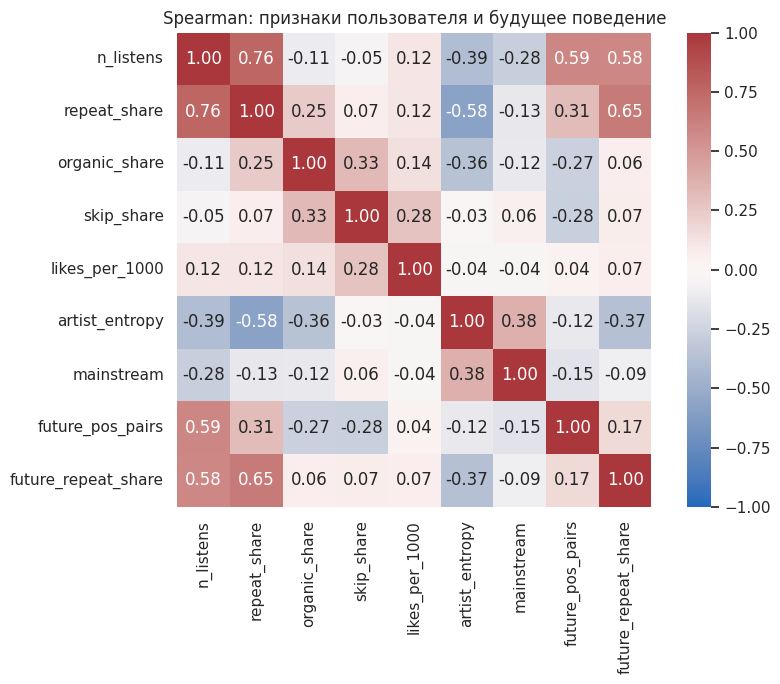

In [22]:
item_src = collect(hist_listens.group_by("item_id").agg(
    pl.len().alias("n"), pl.col("uid").n_unique().alias("users"),
    pl.col("is_organic").sum().alias("n_org"), pl.col("played_ratio_pct").mean().alias("mean_ratio")))
u_listen = collect(hist_listens.group_by("uid").agg(
    pl.len().alias("n_listens"),
    pl.col("item_id").n_unique().alias("n_items"),
    pl.col("is_organic").mean().alias("organic_share"),
    (pl.col("played_ratio_pct") < 30).mean().alias("skip_share"),
)).with_columns((1 - pl.col("n_items") / pl.col("n_listens")).alias("repeat_share"))
u_likes = collect(hist.filter(pl.col("event_type") == "like").group_by("uid").agg(pl.len().alias("n_likes")))
u_main = (hist_pair_stats.select("uid", "item_id").join(item_src.select("item_id", "users"), on="item_id")
          .group_by("uid").agg(pl.col("users").median().alias("mainstream")))
u_entropy = (hist_pair_stats.join(first_artist, on="item_id").group_by("uid", "artist_id").agg(pl.col("n_hist").sum())
             .group_by("uid").agg(pl.col("n_hist").entropy(base=2).alias("h"), pl.len().alias("n_artists"))
             .with_columns(pl.when(pl.col("n_artists") > 1).then(pl.col("h") / pl.col("n_artists").log(2))
                           .otherwise(0.0).alias("artist_entropy")))
u_target = target.filter(pl.col("user_known")).group_by("uid").agg(
    pl.len().alias("future_pos_pairs"), pl.col("heard_before").mean().alias("future_repeat_share"))

user_feats = (u_listen.join(u_likes, on="uid", how="left").join(u_main, on="uid", how="left")
              .join(u_entropy.select("uid", "artist_entropy", "n_artists"), on="uid", how="left")
              .with_columns(pl.col("n_likes").fill_null(0))
              .with_columns((1000 * pl.col("n_likes") / pl.col("n_listens")).alias("likes_per_1000")))
FEATS = ["n_listens", "repeat_share", "organic_share", "skip_share", "likes_per_1000", "artist_entropy", "mainstream"]
corr_df = user_feats.join(u_target, on="uid", how="inner").sort("uid").select(FEATS + ["future_pos_pairs", "future_repeat_share"]).to_pandas()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_df.corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, square=True)
plt.title("Spearman: признаки пользователя и будущее поведение"); plt.tight_layout(); plt.show()



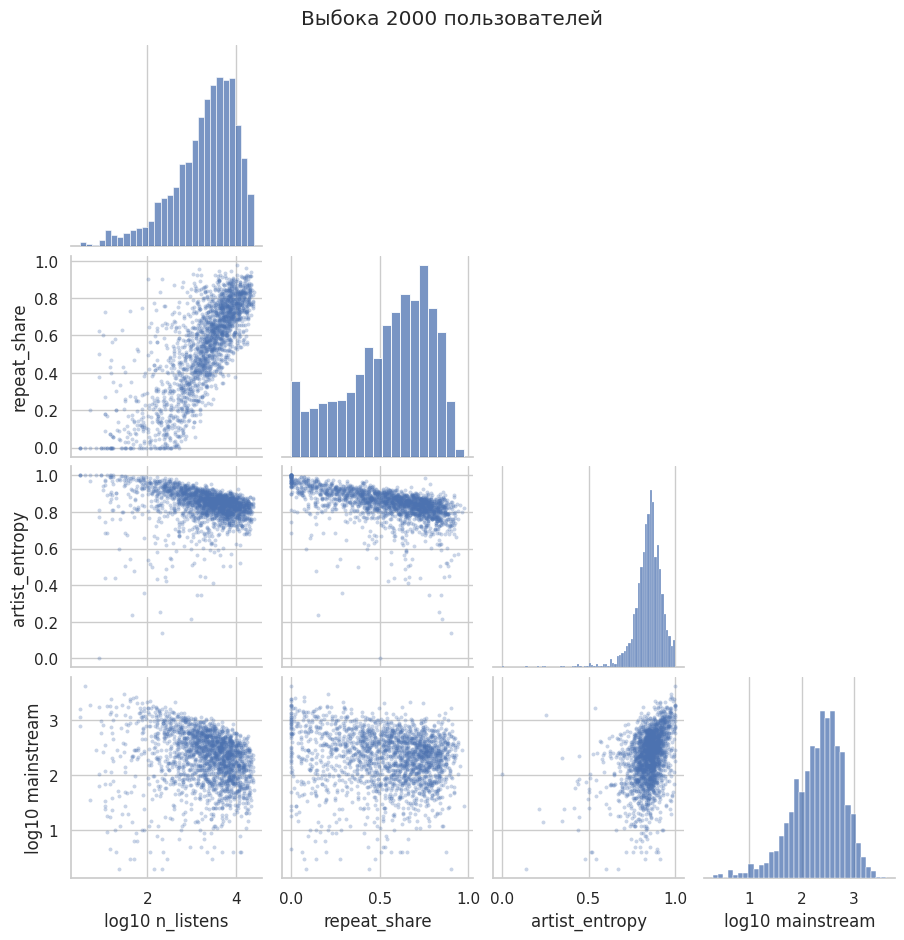

In [23]:
pp = corr_df[["n_listens", "repeat_share", "artist_entropy", "mainstream"]].sample(min(2000, len(corr_df)), random_state=RANDOM_STATE)
pp["n_listens"] = np.log10(pp["n_listens"]); pp["mainstream"] = np.log10(pp["mainstream"] + 1)
g = sns.pairplot(pp.rename(columns={"n_listens": "log10 n_listens", "mainstream": "log10 mainstream"}),
                 corner=True, height=2.3, plot_kws={"s": 8, "alpha": 0.3, "linewidth": 0})
g.fig.suptitle("Выбока 2000 пользователей", y=1.02); plt.show()

Доля повторов в истории связана с будущими повторами (ρ = 0,65), поэтому repeat_share полезен для персонализации. Более узкий круг артистов связан с частыми повторами (ρ = −0,58), а разнообразие артистов - с популярностью прослушиваемых треков (ρ = 0,38).

Органичность связана с долей пропусков (ρ = 0,33), а пропуски - с меньшим числом будущих положительных пар (ρ = −0,28). Лайки на 1 000 прослушиваний показывают слабые связи с остальными признаками.

## 6. Подготовка данных для следующего этапа ML

### 6.1. Фильтрация редких объектов

In [24]:
pos_pairs = hist_pair_stats.filter(pl.col("n_pos_hist") > 0).select("uid", "item_id", pl.col("n_pos_hist").alias("n_pos"))

def filter_pairs(pairs, min_user_items, min_item_users):
    cur, passes = pairs, 0
    while True:
        prev = cur.height
        cur = cur.join(cur.group_by("uid").len().filter(pl.col("len") >= min_user_items).select("uid"), on="uid", how="semi")
        cur = cur.join(cur.group_by("item_id").len().filter(pl.col("len") >= min_item_users).select("item_id"), on="item_id", how="semi")
        passes += 1
        if cur.height == prev:
            return cur, passes

base_events = int(pos_pairs["n_pos"].sum())
variants, rows = {}, []
for t in (1, 3, 5, 10):
    f, passes = filter_pairs(pos_pairs, t, t)
    variants[t] = f
    rows.append({"min_degree": t, "users": f["uid"].n_unique(), "items": f["item_id"].n_unique(), "pairs": f.height,
                 "items_kept_pct": pct(f["item_id"].n_unique(), pos_pairs["item_id"].n_unique()),
                 "pos_events_kept_pct": pct(int(f["n_pos"].sum()), base_events), "passes": passes})
display(pl.DataFrame(rows))

SELECTED = 5
train_pairs = variants[SELECTED]

min_degree,users,items,pairs,items_kept_pct,pos_events_kept_pct,passes
i64,i64,i64,i64,f64,f64,i64
1,8869,582835,7870319,100.0,100.0,1
3,8753,226466,7434475,38.855937,95.73372,3
5,8675,159611,7207845,27.385281,93.445778,3
10,8534,101252,6824754,17.372327,89.41127,3


Выбираю порог 5/5: у пользователя не меньше 5 положительных треков, у трека не меньше 5 положительных слушателей. Остаётся 93,4% положительных событий и 98% пользователей, но только 27% треков. Остальные треки дают меньше 7% событий, и коллаборативный вектор по 1-4 точкам был бы шумом. Для этого хвоста нужна контентная ветка.

In [25]:
m_users = train_pairs.select("uid").unique().with_columns(pl.lit(True).alias("u_in"))
m_items = train_pairs.select("item_id").unique().with_columns(pl.lit(True).alias("i_in"))
cov = (target.join(m_users, on="uid", how="left").join(m_items, on="item_id", how="left")
       .with_columns(pl.col("u_in", "i_in").fill_null(False)))
fut_all = collect(fut.select("uid", "item_id")).join(m_users, on="uid", how="left").join(m_items, on="item_id", how="left").with_columns(pl.col("u_in", "i_in").fill_null(False))

def coverage(df, name, weight=None):
    if weight:
        share = lambda flag: 100 * (pl.col(weight) * flag.cast(pl.Float64)).sum() / pl.col(weight).sum()
    else:
        share = lambda flag: 100 * flag.cast(pl.Float64).mean()
    return df.select(pl.lit(name).alias("scope"), pl.len().alias("rows"),
                     share(pl.col("u_in")).alias("user_in_matrix_pct"),
                     share(pl.col("i_in")).alias("item_in_matrix_pct"),
                     share(pl.col("u_in") & pl.col("i_in")).alias("both_pct"))

display(pl.concat([
    coverage(fut_all, "все события будущего"),
    coverage(cov, "положительные пары будущего"),
    coverage(cov, "положительные события будущего", weight="n"),
    coverage(cov.filter(pl.col("is_new")), "новые положительные пары"),
]))
fi = fut_all.select("item_id", "i_in").unique()
print(f"Треков будущего периода в матрице: {pct(fi['i_in'].sum(), fi.height):.1f}%")

scope,rows,user_in_matrix_pct,item_in_matrix_pct,both_pct
str,u32,f64,f64,f64
"""все события будущего""",6442099,95.740224,86.353811,82.705683
"""положительные пары будущего""",2270787,96.382884,87.396572,84.186936
"""положительные события будущего""",2270787,96.576101,87.49789,84.470756
"""новые положительные пары""",919443,97.992807,89.334086,87.440766


Треков будущего периода в матрице: 37.9%


В матрице 5/5 только 37,9% треков будущего периода, но пользователь и трек есть в ней у 82,7% будущих событий. Для новых положительных пар объектов с историей оба есть в матрице в 87,4% случаев. Это охват, а не метрика качества: остальные пары модели, обученной только на матрице, недоступны.

In [26]:
user_features = user_feats.join(m_users.select("uid"), on="uid", how="semi").sort("uid")
item_features = (m_items.select("item_id")
                 .join(item_src.select("item_id", pl.col("users").alias("item_users"), "mean_ratio",
                                       (pl.col("n_org") / pl.col("n")).alias("item_organic_share")), on="item_id", how="left")
                 .join(item_meta.select("item_id", "n_artists", "n_albums"), on="item_id", how="left")
                 .join(item_len.select("item_id", pl.col("length").alias("length_sec")), on="item_id", how="left")
                 .fill_null(0).sort("item_id"))
pair_features = (hist_pair_stats.join(train_pairs.select("uid", "item_id"), on=["uid", "item_id"], how="semi")
                 .with_columns(((CUTOFF_TS - pl.col("last_ts").cast(pl.Int64)) / SECONDS_PER_DAY).alias("days_since_last"))
                 .drop("last_ts").sort("uid", "item_id"))


### 6.2. Признаки и разреженная матрица

In [27]:
from scipy.sparse import csr_matrix, save_npz

user_index = train_pairs.select("uid").unique().sort("uid").with_row_index("user_idx")
item_index = train_pairs.select("item_id").unique().sort("item_id").with_row_index("item_idx")
idx = train_pairs.join(user_index, on="uid").join(item_index, on="item_id")
assert idx.height == train_pairs.height
shape = (user_index.height, item_index.height)
rows_, cols_ = idx["user_idx"].to_numpy(), idx["item_idx"].to_numpy()

X_bin = csr_matrix((np.ones(idx.height, dtype=np.float32), (rows_, cols_)), shape=shape)
X_log = csr_matrix((np.log1p(idx["n_pos"].to_numpy()).astype(np.float32), (rows_, cols_)), shape=shape)
X_csc = X_bin.tocsc()
assert X_bin.nnz == train_pairs.height
assert X_bin.getnnz(axis=1).min() >= SELECTED and X_bin.getnnz(axis=0).min() >= SELECTED

csr_bytes = X_bin.data.nbytes + X_bin.indices.nbytes + X_bin.indptr.nbytes
display(pl.DataFrame({
    "users": [shape[0]], "items": [shape[1]], "nnz": [X_bin.nnz],
    "density_pct": [100 * X_bin.nnz / (shape[0] * shape[1])],
    "dense_float32_GiB": [shape[0] * shape[1] * 4 / 1024**3],
    "csr_MiB": [csr_bytes / 1024**2],
}))

artist_links = item_artist.join(item_index, on="item_id")
artist_index = artist_links.select("artist_id").unique().sort("artist_id").with_row_index("artist_idx")
artist_links = artist_links.join(artist_index, on="artist_id")
X_artist = csr_matrix((np.ones(artist_links.height, dtype=np.float32),
                       (artist_links["item_idx"].to_numpy(), artist_links["artist_idx"].to_numpy())),
                      shape=(item_index.height, artist_index.height))
print("Трек × артист:", X_artist.shape, "треков без артиста:", int((X_artist.getnnz(axis=1) == 0).sum()))

users,items,nnz,density_pct,dense_float32_GiB,csr_MiB
i64,i64,i64,f64,f64,f64
8675,159611,7207845,0.520563,5.158132,55.02459


Трек × артист: (159611, 24533) треков без артиста: 3


Признаки считаю только по истории до 271-го дня. Плотная матрица 8 675 x 159 611 заняла бы 5,16 GiB, в CSR она весит 55 MiB при плотности 0,52%. CSR удобен для операций по пользователям, CSC по трекам. Строю две версии весов, бинарную и `log1p(count)`, и сравню их в чекпоинте 3.

## 7. Коллаборативные представления треков и SVD

Проверяю, есть ли у коллаборативных векторов треков осмысленная структура ещё до обучения моделей. Факторизую матрицу из раздела 6 (веса `log1p(count)`) до 32 компонент и для сходства нормирую векторы.

In [28]:
import time
from sklearn.decomposition import TruncatedSVD

# Матрица, индексы и признаки из раздела 6
X = X_log
pair_pos = pair_features.select("item_id", "n_pos_hist")
assert item_features["item_id"].equals(item_index["item_id"]) and X.shape[1] == X_artist.shape[0]

In [29]:
item_pop = (
    item_index
    .join(pair_pos.group_by("item_id").agg(pl.col("n_pos_hist").sum().alias("pos_events")), on="item_id", how="left")
    .join(item_features.select("item_id", "item_users"), on="item_id", how="left")
    .with_columns(pl.col("pos_events", "item_users").fill_null(0))
    .sort(["pos_events", "item_id"], descending=[True, False])
    .with_columns((pl.col("pos_events").cum_sum() / pl.col("pos_events").sum()).alias("cum"))
    .with_columns(pl.when(pl.col("cum") <= 0.5).then(pl.lit("голова"))
                  .when(pl.col("cum") <= 0.9).then(pl.lit("середина"))
                  .otherwise(pl.lit("хвост")).alias("group"))
    .sort("item_idx")
)
GROUPS = ["голова", "середина", "хвост"]
group_arr = item_pop["group"].to_numpy()
users_arr = item_pop["item_users"].to_numpy()
display(item_pop.group_by("group").agg(
    pl.len().alias("n_items"), pl.col("item_users").median().alias("median_users"),
    pl.col("item_users").min().alias("min_users"), pl.col("pos_events").sum().alias("pos_events"),
).sort(pl.col("group").replace_strict({g: i for i, g in enumerate(GROUPS)})))

group,n_items,median_users,min_users,pos_events
str,u32,f64,u32,u32
"""голова""",7399,457.0,8,11808753
"""середина""",52040,61.0,5,9447628
"""хвост""",100172,12.0,5,2361858


In [30]:
try:
    import psutil
    rss = lambda: psutil.Process().memory_info().rss / 1024**2
except ImportError:
    rss = lambda: float("nan")

SVD_PARAMS = dict(n_components=32, algorithm="randomized", n_iter=7, random_state=RANDOM_STATE)
Xt = X.T.tocsr()
rss_before, t0 = rss(), time.perf_counter()
svd = TruncatedSVD(**SVD_PARAMS)
item_vecs = svd.fit_transform(Xt).astype(np.float32)
fit_sec, rss_after = time.perf_counter() - t0, rss()

norms = np.linalg.norm(item_vecs, axis=1)
zero = norms < 1e-8
item_emb = np.zeros_like(item_vecs)
item_emb[~zero] = item_vecs[~zero] / norms[~zero, None]

svd_stats = {
    **{k: v for k, v in SVD_PARAMS.items()},
    "input_shape": list(Xt.shape), "output_shape": list(item_vecs.shape),
    "fit_seconds": round(fit_sec, 2),
    "rss_delta_MiB": round(rss_after - rss_before, 1),
    "item_vecs_MiB": round(item_vecs.nbytes / 1024**2, 2),
    "non_finite_values": int((~np.isfinite(item_vecs)).sum()),
    "zero_vectors": int(zero.sum()),
    "explained_variance_ratio_sum": round(float(svd.explained_variance_ratio_.sum()), 4),
    "first_component_ratio": round(float(svd.explained_variance_ratio_[0]), 4),
    "spearman_norm_vs_users": round(pl.DataFrame({"a": norms, "b": users_arr}).select(pl.corr("a", "b", method="spearman")).item(), 3),
    "spearman_comp1_vs_users": round(pl.DataFrame({"a": np.abs(item_vecs[:, 0]), "b": users_arr}).select(pl.corr("a", "b", method="spearman")).item(), 3),
}
display(pl.DataFrame([{k: str(v) for k, v in svd_stats.items()}]).transpose(include_header=True, header_name="metric", column_names=["value"]))



metric,value
str,str
"""n_components""","""32"""
"""algorithm""","""randomized"""
"""n_iter""","""7"""
"""random_state""","""42"""
"""input_shape""","""[159611, 8675]"""
"""output_shape""","""[159611, 32]"""
"""fit_seconds""","""5.55"""
"""rss_delta_MiB""","""-56.7"""
"""item_vecs_MiB""","""19.48"""


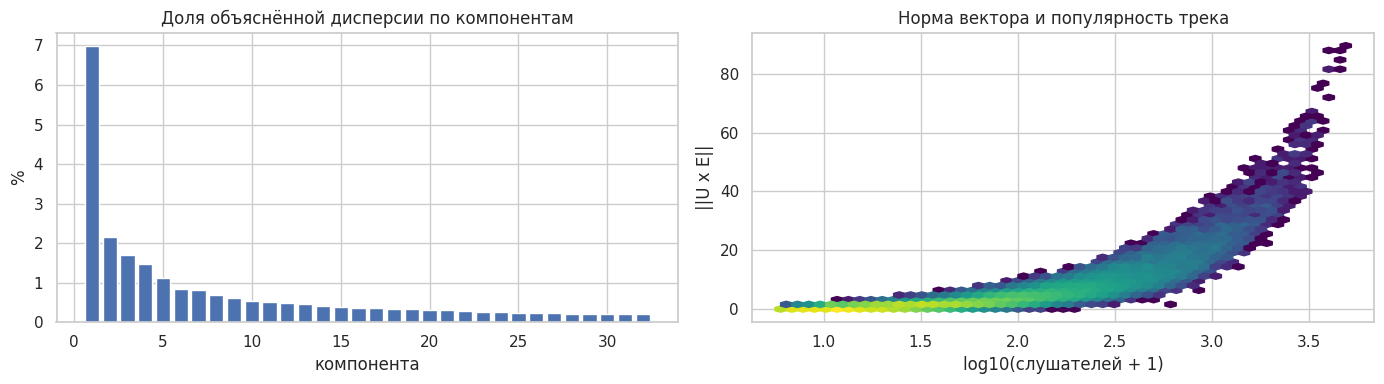

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(np.arange(1, 33), 100 * svd.explained_variance_ratio_)
axes[0].set(title="Доля объяснённой дисперсии по компонентам", xlabel="компонента", ylabel="%")
axes[1].hexbin(np.log10(users_arr + 1), norms, gridsize=50, bins="log", cmap="viridis")
axes[1].set(title="Норма вектора и популярность трека", xlabel="log10(слушателей + 1)", ylabel="||U x E||")
plt.tight_layout(); plt.show()

Нечисловых значений и нулевых векторов нет, SVD обучается за несколько секунд. 32 компоненты объясняют 23,8% дисперсии, первая втрое больше второй. Норма вектора сильно связана с популярностью трека, поэтому сходство считаю по косинусу.

UMAP на 15,000 треках: 108.1 с


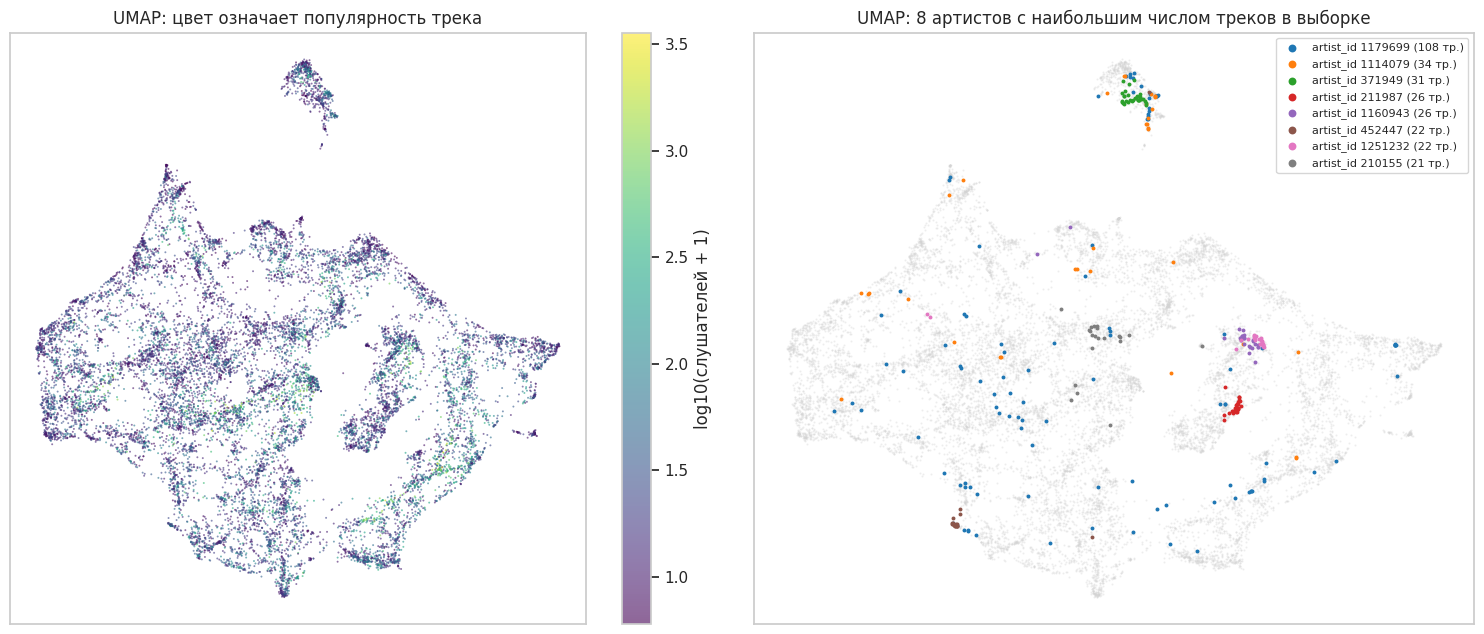

In [32]:
import warnings
warnings.filterwarnings("ignore", message="n_jobs value")
try:
    import umap
    METHOD = "UMAP"
except ImportError:
    from sklearn.decomposition import PCA
    METHOD = "PCA"

N_PROJ = 15000
rng = np.random.default_rng(RANDOM_STATE + 2)
proj_rows = np.sort(rng.choice(np.flatnonzero(~zero), min(N_PROJ, int((~zero).sum())), replace=False))
t0 = time.perf_counter()
if METHOD == "UMAP":
    reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=RANDOM_STATE)
else:
    reducer = PCA(n_components=2, random_state=RANDOM_STATE)
xy = reducer.fit_transform(item_emb[proj_rows])
print(f"{METHOD} на {proj_rows.size:,} треках: {time.perf_counter() - t0:.1f} с")

first_artist_idx = np.full(X_artist.shape[0], -1)
has_a = X_artist.getnnz(axis=1) > 0
first_artist_idx[has_a] = X_artist.indices[X_artist.indptr[:-1][has_a]]
art = first_artist_idx[proj_rows]
artist_ids = artist_index.sort("artist_idx")["artist_id"].to_numpy()
top_art = [a for a, _ in sorted(zip(*np.unique(art[art >= 0], return_counts=True)), key=lambda t: (-t[1], t[0]))[:8]]

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
sc = axes[0].scatter(xy[:, 0], xy[:, 1], c=np.log10(users_arr[proj_rows] + 1), s=2, cmap="viridis", alpha=0.6, linewidths=0)
plt.colorbar(sc, ax=axes[0], label="log10(слушателей + 1)")
axes[0].set(title=f"{METHOD}: цвет означает популярность трека", xticks=[], yticks=[])
axes[1].scatter(xy[:, 0], xy[:, 1], c="lightgray", s=2, alpha=0.4, linewidths=0)
for j, a in enumerate(top_art):
    m = art == a
    axes[1].scatter(xy[m, 0], xy[m, 1], s=8, color=plt.cm.tab10(j), label=f"artist_id {artist_ids[a]} ({m.sum()} тр.)", linewidths=0)
axes[1].legend(markerscale=2, fontsize=8, loc="best")
axes[1].set(title=f"{METHOD}: 8 артистов с наибольшим числом треков в выборке", xticks=[], yticks=[])
plt.tight_layout(); plt.show()

На UMAP-проекции 15 000 треков видны компактные группы одного артиста и отдельный остров, занятый в основном двумя исполнителями. Векторы, построенные только по прослушиваниям, собирают треки одного артиста вместе, хотя об артистах модель ничего не знает. Некоторые артисты разбросаны по карте, так что артист жанр не заменяет. Проекция иллюстрирует структуру, но расстояния между далёкими группами интерпретировать нельзя.

В чекпоинте 3 можно сравнить ItemKNN на SVD-векторах, ItemKNN на исходной матрице и iALS.

## 8. Итоги EDA

1. Данные пригодны для построения рекомендательной системы. Пропуски есть только у реакций, они структурные, ошибочных значений проверки не нашли, точные дубликаты удалены.

2. В выборке есть отбор: все пользователи активны в конце периода, и никто не уходит. Тренды во времени описывают когорту, а не сервис.

3. Распределения имеют тяжёлые хвосты: небольшая часть треков и артистов собирает основную массу прослушиваний. Популярные объекты здесь главный сигнал, поэтому я использую ранговые статистики и логарифмированные счётчики, а популярные треки не удаляю как выбросы.

4. Большая часть будущих положительных взаимодействий составляют повторы уже знакомых треков. Я рекомендую новые треки пользователям и трекам с историей, поэтому знакомые треки исключаю из выдачи, а повторы и холодный старт оцениваю отдельно.

5. После фильтрации в матрице остаётся меньшая часть треков, зато почти все положительные события. Хвост и холодные треки в матрицу не попадают, для них понадобится контентная ветка.

6. Даже простое SVD-разложение даёт осмысленные векторы: на проекции треки одного артиста собираются вместе. Популярность закодирована в длине вектора, поэтому сходство считаю по косинусу.

Ограничения: пользователи анонимны, жанров нет, выборка смещена к активным в конце периода, а часть событий порождена текущей системой, поэтому офлайн-метрики отчасти показывают, насколько модель повторяет её выбор.